### Feature Set A: Standardized Testing PerformanceTarget Feature: Aptitude_Test_Score(Continuous score scale tracking raw analytical capability).

0        49.5
1        72.0
2        79.1
3        48.4
4        61.2
         ... 
99995    67.4
99996    59.5
99997    55.1
99998    65.0
99999    64.5
Name: aptitude_score, Length: 100000, dtype: float64
Distrubution: Continuous, Normal
Skewness: -0.0029255396912280054
Range: 20.0 - 100.0


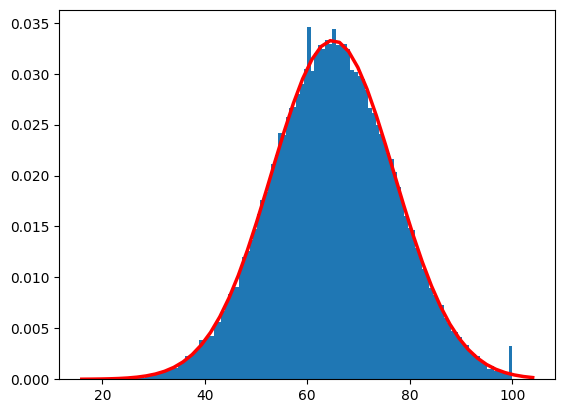

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

data = pd.read_csv("student_placement_synthetic.csv")

aptitude_score = data["aptitude_score"]

skewness = aptitude_score.skew()

print(aptitude_score)
print("Distrubution: Continuous, Normal")
print(f"Skewness: {skewness}")
print(f"Range: {aptitude_score.min()} - {aptitude_score.max()}")
loc, scale = stats.norm.fit(aptitude_score)
# Graph
plt.hist(aptitude_score, bins="auto", label="Aptitude_Test_Score Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)
pdf = stats.norm.pdf(x, loc=loc, scale=scale)
plt.plot(x, pdf, "r-", linewidth=2.5, label="Fitted Normal PDF")
plt.show()


### Feature Set B: Graduate Compensation PackagesTarget Feature: Salary (Continuous values tracking placed student packages in LPA).

0        14.75
1          NaN
2        19.06
3          NaN
4        13.42
         ...  
99995      NaN
99996    16.58
99997    17.24
99998    17.01
99999    14.98
Name: salary_package_lpa, Length: 100000, dtype: float64
Skewness: 0.11420013849552117
Classification: Continuous, Gamma
Range: 6.88 - 28.33


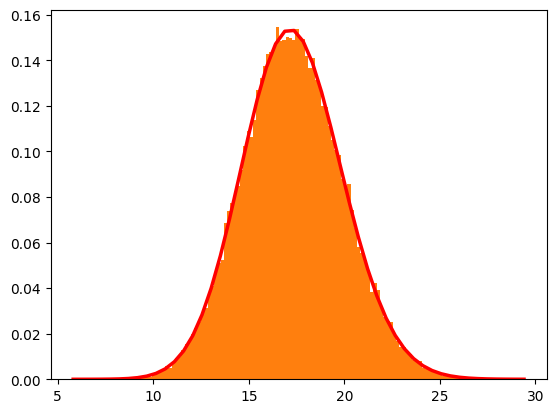

In [22]:
salary = data["salary_package_lpa"]

skewness = salary.skew()
print(salary)
print(f"Skewness: {skewness}")
print("Classification: Continuous, Gamma")
print(f"Range: {salary.min()} - {salary.max()}")

plt.hist(salary, bins="auto", density=True)

salary_clean = salary.dropna()
shape, location, scale = stats.gamma.fit(salary_clean)

plt.hist(salary, bins="auto", label="Nodule_Size Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)
pdf = stats.gamma.pdf(x, shape, location, scale)
plt.plot(x, pdf, "r-", linewidth=2.5, label="Fitted Gamma PDF")
plt.show()

### Feature Set C: Portfolio Engineering MetricsTarget Feature: Projects_Completed or Certifications (Discrete counts of academic milestones).

Skewness: 0    0.189901
dtype: float64
Classification: Discrete, Binomial
Range: 0 - 9


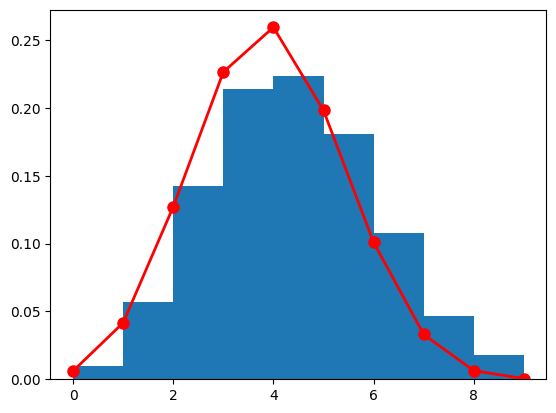

In [23]:
projects_count = data["projects_count"]
certifications = data["certifications"]

metrics = data["projects_count"] + data["certifications"]

skewness = pd.DataFrame(metrics).skew()

print(f"Skewness: {skewness}")
print("Classification: Discrete, Binomial")
print(f"Range: {metrics.min()} - {metrics.max()}")


plt.hist(metrics, bins="auto", label="Engineering metrics Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)

max_val = int(metrics.max())

probability = np.mean(metrics) / max_val
pmf_values = stats.binom.pmf(np.arange(0, max_val + 1), max_val, probability)
plt.plot(np.arange(0, max_val + 1), pmf_values, "ro-", linewidth=2, markersize=8, label=f"Binomial PMF (n=4, p={probability:.2f})",)
plt.show()

### Feature Set D: Random Cohort Employment TrialsFeature Setup: Group the final binary outcome column Placement_Status (Placed vs Not Placed) into independent chunks of exactly N=20 students each. Count the total number of successful Placed outcomes within each 20-student subset.

Skewness: 0   -0.232729
dtype: float64
Classification: Discrete, Binomial
Range: 6 - 20


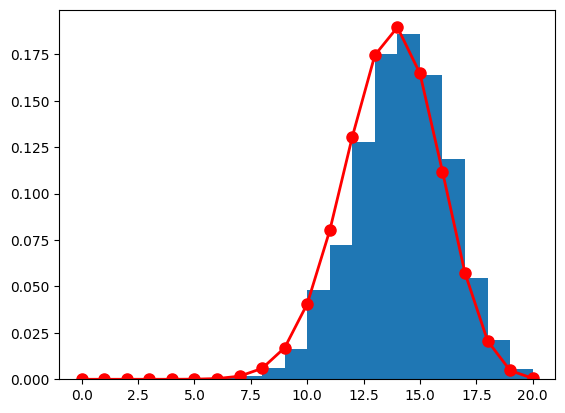

In [24]:
placement_status = data["placement_status"]

chunk_size = 20
total_chunks = int(len(data) / chunk_size)

placed_counts = []

for i in range(total_chunks):
    start = i * chunk_size
    end = start + chunk_size
    chunk = placement_status.iloc[start:end]
    count = chunk.sum()
    placed_counts.append(count)

skewness = pd.DataFrame(placed_counts).skew()

print(f"Skewness: {skewness}")
print("Classification: Discrete, Binomial")
print(f"Range: {min(placed_counts)} - {max(placed_counts)}")


plt.hist(placed_counts, bins="auto", label="Malignant_Counts Histogram", density=True)
x_min, x_max = plt.xlim()
x = np.linspace(x_min, x_max, 50)

probability = np.mean(placed_counts) / chunk_size
pmf_values = stats.binom.pmf(np.arange(0, chunk_size + 1), chunk_size, probability)
plt.plot(np.arange(0, chunk_size + 1), pmf_values, "ro-", linewidth=2, markersize=8, label=f"Binomial PMF (n={chunk_size}, p={probability:.2f})")
plt.show()